<a href="https://colab.research.google.com/github/gerardagustina/breast-cancer-survival-analysis/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Exploratory Data Analysis: GBSG2 breast cancer trial
Time-to-recurrence analysis of 686 patients from the German Breast Cancer Study Group 2 trial.

In [55]:
!pip install -q lifelines

In [56]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines.datasets import load_gbsg2

os.makedirs("figures", exist_ok=True)  # NEW

df = load_gbsg2()
print(df.shape)
df.head()

(686, 10)


,horTh,age,menostat,tsize,tgrade,pnodes,progrec,estrec,time,cens
0,no,70,Post,21,II,3,48,66,1814,1
1,yes,56,Post,12,II,7,61,77,2018,1
2,yes,58,Post,35,II,9,52,271,712,1
3,yes,59,Post,17,II,4,60,29,1807,1
4,no,73,Post,35,II,1,26,65,772,1


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 686 entries, 0 to 685
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   horTh     686 non-null    object
 1   age       686 non-null    int64 
 2   menostat  686 non-null    object
 3   tsize     686 non-null    int64 
 4   tgrade    686 non-null    object
 5   pnodes    686 non-null    int64 
 6   progrec   686 non-null    int64 
 7   estrec    686 non-null    int64 
 8   time      686 non-null    int64 
 9   cens      686 non-null    int64 
dtypes: int64(7), object(3)
memory usage: 53.7+ KB


In [58]:
n_events = df["cens"].sum()
n_censored = (df["cens"] == 0).sum()

print(f"Eventos (recaída o muerte): {n_events} ({n_events / len(df):.1%})")
print(f"Censuradas:                 {n_censored} ({n_censored / len(df):.1%})")

Eventos (recaída o muerte): 299 (43.6%)
Censuradas:                 387 (56.4%)


In [59]:
df.describe().round(1)

,age,tsize,pnodes,progrec,estrec,time,cens
count,686.0,686.0,686.0,686.0,686.0,686.0,686.0
mean,53.1,29.3,5.0,110.0,96.3,1124.5,0.4
std,10.1,14.3,5.5,202.3,153.1,642.8,0.5
min,21.0,3.0,1.0,0.0,0.0,8.0,0.0
25%,46.0,20.0,1.0,7.0,8.0,567.8,0.0
50%,53.0,25.0,3.0,32.5,36.0,1084.0,0.0
75%,61.0,35.0,7.0,131.8,114.0,1684.8,1.0
max,80.0,120.0,51.0,2380.0,1144.0,2659.0,1.0


In [60]:
for col in ["horTh", "menostat", "tgrade"]:
    print(df[col].value_counts(), "\n")

horTh
no     440
yes    246
Name: count, dtype: int64 

menostat
Post    396
Pre     290
Name: count, dtype: int64 

tgrade
II     444
III    161
I       81
Name: count, dtype: int64 



In [61]:
for col in ["horTh", "menostat", "tgrade"]:
    print((df[col].value_counts(normalize=True) * 100).round(1), "\n")

horTh
no     64.1
yes    35.9
Name: proportion, dtype: float64 

menostat
Post    57.7
Pre     42.3
Name: proportion, dtype: float64 

tgrade
II     64.7
III    23.5
I      11.8
Name: proportion, dtype: float64 



In [62]:
df.groupby("horTh")[["age", "tsize", "pnodes", "progrec", "estrec"]].median()

,age,tsize,pnodes,progrec,estrec
horTh,,,,,
no,50.0,25.0,3.0,32.0,32.0
yes,58.0,25.0,3.0,35.0,46.0


In [63]:
for col in ["menostat", "tgrade"]:
    print((pd.crosstab(df["horTh"], df[col], normalize="index") * 100).round(1), "\n")

menostat  Post   Pre
horTh               
no        47.5  52.5
yes       76.0  24.0 

tgrade     I    II   III
horTh                   
no      10.9  63.9  25.2
yes     13.4  66.3  20.3 



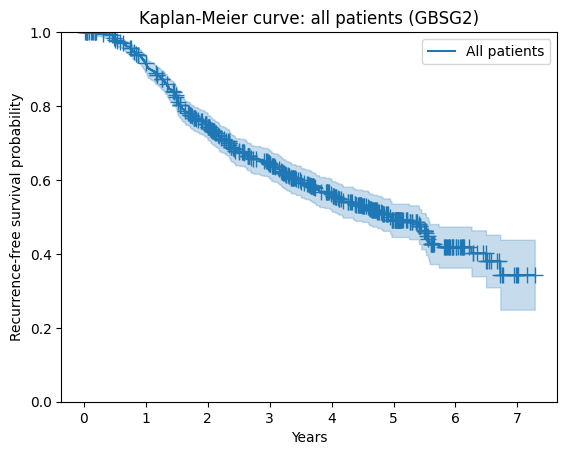

Median recurrence-free survival: 4.95 years


In [64]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
kmf.fit(durations=df["time"] / 365.25, event_observed=df["cens"], label="All patients")

kmf.plot_survival_function(show_censors=True, ci_show=True)
plt.xlabel("Years")
plt.ylabel("Recurrence-free survival probability")
plt.title("Kaplan-Meier curve: all patients (GBSG2)")
plt.ylim(0, 1)
plt.savefig("figures/km_overall.png", dpi=150, bbox_inches="tight")  # NEW
plt.show()

print(f"Median recurrence-free survival: {kmf.median_survival_time_:.2f} years")

Hormone therapy no: median = 4.18 years
Hormone therapy yes: median = 5.52 years


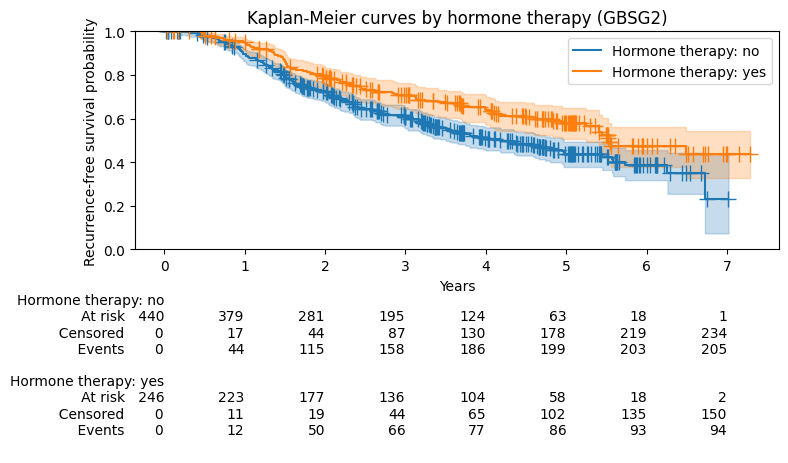

In [65]:
from lifelines.plotting import add_at_risk_counts

fig, ax = plt.subplots(figsize=(8, 5))
fitters = []

for group in ["no", "yes"]:
    mask = df["horTh"] == group
    kmf_g = KaplanMeierFitter()
    kmf_g.fit(
        durations=df.loc[mask, "time"] / 365.25,
        event_observed=df.loc[mask, "cens"],
        label=f"Hormone therapy: {group}",
    )
    kmf_g.plot_survival_function(ax=ax, show_censors=True, ci_show=True)
    fitters.append(kmf_g)
    print(f"Hormone therapy {group}: median = {kmf_g.median_survival_time_:.2f} years")

add_at_risk_counts(*fitters, ax=ax)
ax.set_xlabel("Years")
ax.set_ylabel("Recurrence-free survival probability")
ax.set_title("Kaplan-Meier curves by hormone therapy (GBSG2)")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("figures/km_by_treatment.png", dpi=150, bbox_inches="tight")  # NEW
plt.show()

In [66]:
from lifelines.statistics import logrank_test

treated = df["horTh"] == "yes"

result = logrank_test(
    durations_A=df.loc[treated, "time"],
    durations_B=df.loc[~treated, "time"],
    event_observed_A=df.loc[treated, "cens"],
    event_observed_B=df.loc[~treated, "cens"],
)
print(f"p-value: {result.p_value:.4f}")

p-value: 0.0034


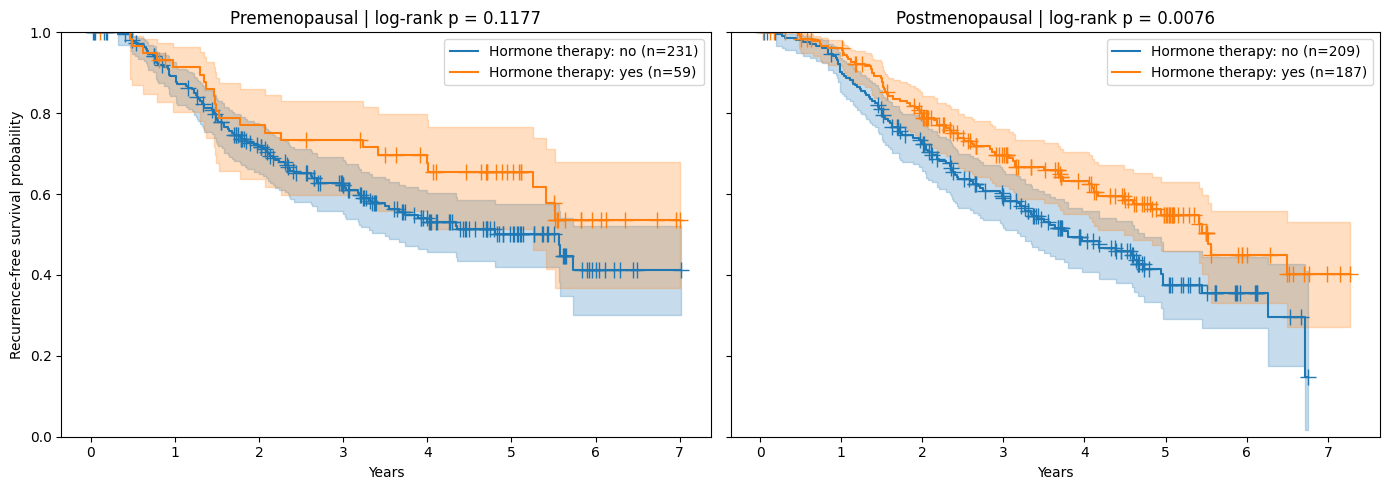

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, status in zip(axes, ["Pre", "Post"]):
    stratum = df["menostat"] == status

    for group in ["no", "yes"]:
        mask = stratum & (df["horTh"] == group)
        kmf_g = KaplanMeierFitter()
        kmf_g.fit(
            durations=df.loc[mask, "time"] / 365.25,
            event_observed=df.loc[mask, "cens"],
            label=f"Hormone therapy: {group} (n={mask.sum()})",
        )
        kmf_g.plot_survival_function(ax=ax, show_censors=True, ci_show=True)

    treated_s = stratum & (df["horTh"] == "yes")
    control_s = stratum & (df["horTh"] == "no")
    res = logrank_test(
        durations_A=df.loc[treated_s, "time"],
        durations_B=df.loc[control_s, "time"],
        event_observed_A=df.loc[treated_s, "cens"],
        event_observed_B=df.loc[control_s, "cens"],
    )

    ax.set_title(f"{status}menopausal | log-rank p = {res.p_value:.4f}")
    ax.set_xlabel("Years")
    ax.set_ylim(0, 1)

axes[0].set_ylabel("Recurrence-free survival probability")
plt.tight_layout()
plt.savefig("figures/km_by_treatment_stratified.png", dpi=150, bbox_inches="tight")  # NEW
plt.show()

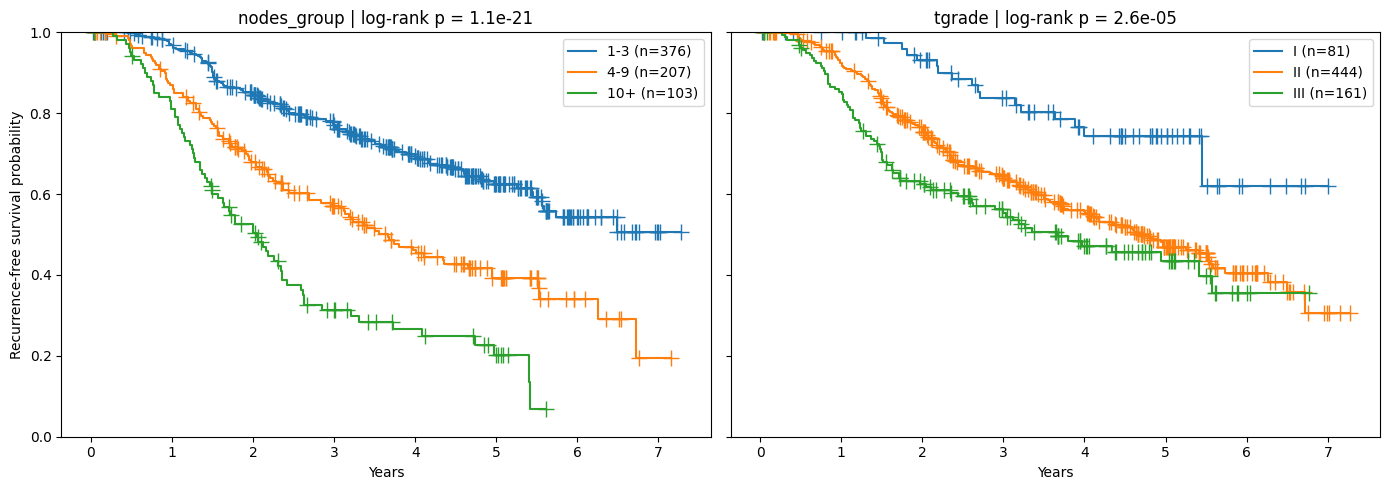

In [68]:
from lifelines.statistics import multivariate_logrank_test

df["nodes_group"] = pd.cut(df["pnodes"], bins=[0, 3, 9, np.inf], labels=["1-3", "4-9", "10+"])

groupings = {
    "nodes_group": ["1-3", "4-9", "10+"],
    "tgrade": ["I", "II", "III"],
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (var, levels) in zip(axes, groupings.items()):
    for level in levels:
        mask = df[var] == level
        kmf_g = KaplanMeierFitter()
        kmf_g.fit(
            durations=df.loc[mask, "time"] / 365.25,
            event_observed=df.loc[mask, "cens"],
            label=f"{level} (n={mask.sum()})",
        )
        kmf_g.plot_survival_function(ax=ax, show_censors=True, ci_show=False)

    res = multivariate_logrank_test(df["time"], df[var], df["cens"])
    ax.set_title(f"{var} | log-rank p = {res.p_value:.2g}")
    ax.set_xlabel("Years")
    ax.set_ylim(0, 1)

axes[0].set_ylabel("Recurrence-free survival probability")
plt.tight_layout()
plt.savefig("figures/km_prognostic_factors.png", dpi=150, bbox_inches="tight")  # NEW
plt.show()

In [69]:
from google.colab import files

!zip -r -q figures.zip figures
files.download("figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>